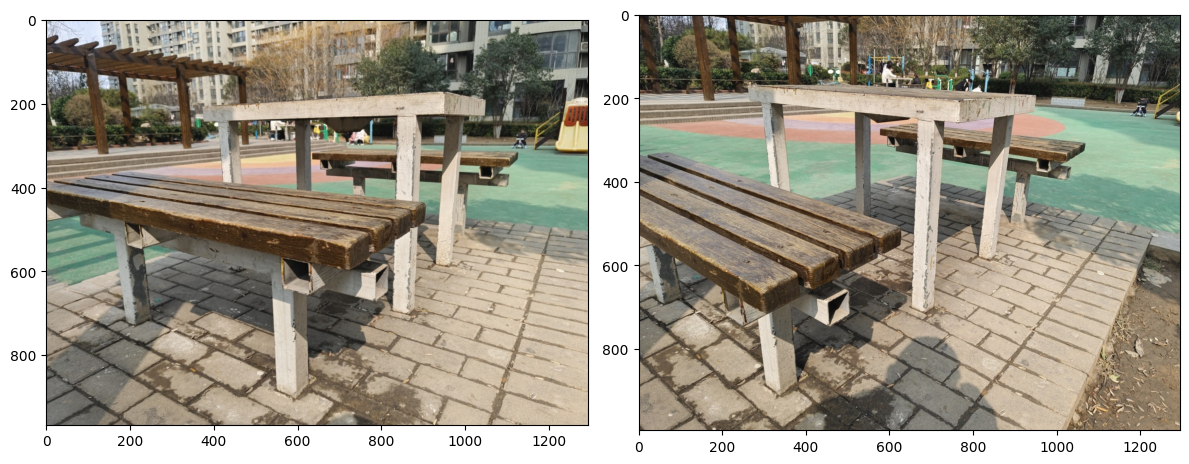

In [1]:
import cv2 
import numpy as np
import  matplotlib.pyplot as plt
image_0000_bgr = cv2.imread('./GardenDeskOriginal/images/0000.jpg')
image_0000 = cv2.cvtColor(image_0000_bgr,cv2.COLOR_BGR2RGB)
image_0001_bgr = cv2.imread('./GardenDeskOriginal/images/0001.jpg')
image_0001 = cv2.cvtColor(image_0001_bgr,cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(image_0000)

plt.subplot(1,2,2)
plt.imshow(image_0001)
plt.tight_layout()
plt.show()


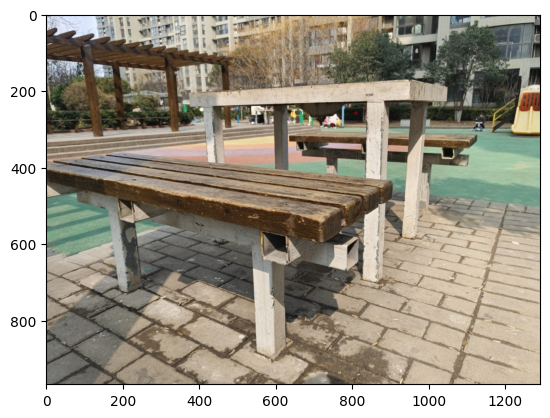

(< cv2.KeyPoint 0x7fd152c1a0a0>, < cv2.KeyPoint 0x7fd1529f6010>, < cv2.KeyPoint 0x7fd1529f6160>, < cv2.KeyPoint 0x7fd1529f6250>, < cv2.KeyPoint 0x7fd1529f4750>, < cv2.KeyPoint 0x7fd1529f6220>, < cv2.KeyPoint 0x7fd1529d3120>, < cv2.KeyPoint 0x7fd1529d3f90>, < cv2.KeyPoint 0x7fd1529d1260>, < cv2.KeyPoint 0x7fd1529d1230>)
[[37. 40. 14. ...  0.  0.  1.]
 [44. 56.  8. ...  0.  0.  0.]
 [10.  7.  1. ... 22. 14.  0.]
 ...
 [40. 99. 14. ... 45. 31.  8.]
 [ 2.  0.  0. ... 40. 14.  4.]
 [ 7. 18. 58. ... 41. 36.  0.]]
(10, 128)


In [24]:
import cv2 
import numpy as np 
import matplotlib.pyplot as plt
image_0000_bgr = cv2.imread('./GardenDeskOriginal/images/0000.jpg')
b,g,r = cv2.split(bgr_lakes02)
image_0000_rgb = cv2.merge((r,g,b))
#rgb_lakes02 = cv2.resize(rgb_lakes02,(0,0),fx=1/8,fy=1/8)
gray_0000 = cv2.cvtColor(image_0000_rgb,cv2.COLOR_RGB2GRAY)

sift_detector = cv2.SIFT_create(nfeatures=10,contrastThreshold=0.1)
keypoints_image_0000, descriptors_image_0000 = sift_detector.detectAndCompute(gray_0000,None)
keypoints_image_0000_canvas = cv2.drawKeypoints(image_0000_rgb.copy(),keypoints_lakes02,cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,(255,0,0))

plt.imshow(keypoints_image_0000_canvas)
plt.show()
print(keypoints_image_0000)
print(descriptors_image_0000)
print(descriptors_image_0000.shape)

In [25]:
for i,kp in enumerate(keypoints_image_0000):
    kp = keypoints_image_0000[i]

    print("Position:", kp.pt)
    print("X:", kp.pt[0])
    print("Y:", kp.pt[1])

    print("Size:", kp.size)
    print("Angle:", kp.angle)
    print("Response:", kp.response)
    print("Octave:", kp.octave)
    print("Class ID:", kp.class_id)

Position: (298.5722351074219, 64.58885955810547)
X: 298.5722351074219
Y: 64.58885955810547
Size: 3.342424154281616
Angle: 258.8318176269531
Response: 0.0834498479962349
Octave: 11535359
Class ID: -1
Position: (18.357641220092773, 245.01136779785156)
X: 18.357641220092773
Y: 245.01136779785156
Size: 8.957930564880371
Angle: 140.35549926757812
Response: 0.08370386809110641
Octave: 15991041
Class ID: -1
Position: (18.357641220092773, 245.01136779785156)
X: 18.357641220092773
Y: 245.01136779785156
Size: 8.957930564880371
Angle: 348.7611083984375
Response: 0.08370386809110641
Octave: 15991041
Class ID: -1
Position: (748.1685180664062, 290.1017150878906)
X: 748.1685180664062
Y: 290.1017150878906
Size: 7.778971195220947
Angle: 277.3620300292969
Response: 0.09469486773014069
Octave: 5767425
Class ID: -1
Position: (405.6828918457031, 249.61143493652344)
X: 405.6828918457031
Y: 249.61143493652344
Size: 6.187328815460205
Angle: 305.22283935546875
Response: 0.08735756576061249
Octave: 5899008
Clas

# keypoints的属性
| 属性 | 含义 |
|---|---|
| `pt` | 特征点中心坐标 `(x, y)` |
| `size` | 特征点尺度，表示特征区域的直径大小 |
| `angle` | 特征点主方向，单位为度（°） |
| `response` | 特征点响应强度，用于衡量特征点的显著程度 |
| `octave` | 特征点所在的图像金字塔层级 |
| `class_id` | 特征点的用户自定义标识 |

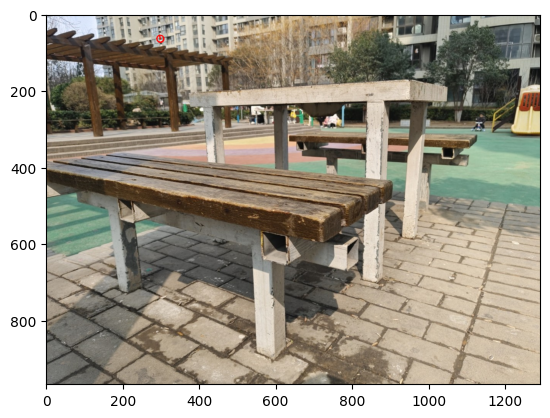

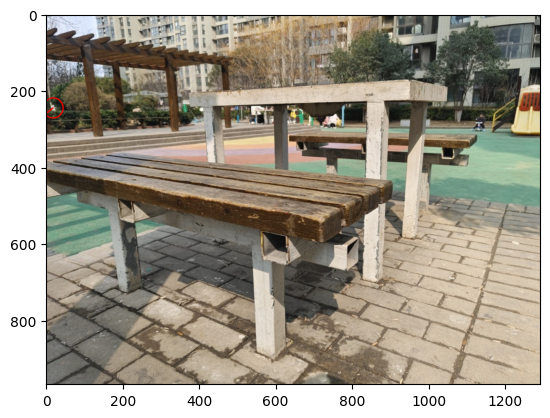

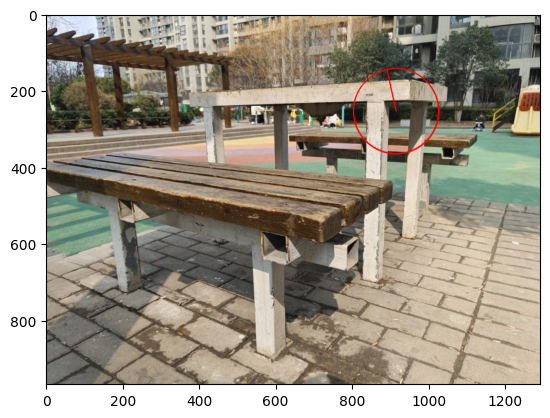

In [34]:
#create a new keypoint with 特征点尺寸为原来的scale倍
def draw_sift_keypoint(img, kp, color=(255, 0, 0), scale=3,thickness = 2):
 
    kp_new = cv2.KeyPoint(
        x=kp.pt[0],
        y=kp.pt[1],
        size=kp.size * scale,
        angle=kp.angle,
        response=kp.response,
        octave=kp.octave,
        class_id=kp.class_id
    )

    kpImg = cv2.drawKeypoints(
        img.copy(),
        [kp_new],
        None,
        color=color,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )
    x = kp_new.pt[0]
    y = kp_new.pt[1]
    radius = (kp_new.size-1)/2
    x = int(x)
    y = int(y)
    radius = int(radius)
    kpImg = cv2.circle(kpImg,(x,y),radius,color,thickness)
    # 2. 计算方向线终点
    angle = np.deg2rad(kp.angle)

    x2 = int(x + radius * np.cos(angle))
    y2 = int(y + radius * np.sin(angle))

    # 3. 绘制加粗方向线
    kpImg =cv2.line(
        kpImg,
        (x, y),
        (x2, y2),
        color,
        thickness,
        lineType=cv2.LINE_AA
    )

    return kpImg

scale = 6
kp =keypoints_image_0000[0]
kpImage = draw_sift_keypoint(image_0000.copy(), kp, color=(255,0,0), scale=scale)
plt.imshow(kpImage)
plt.show()


kp =keypoints_image_0000[1]
kpImage = draw_sift_keypoint(image_0000.copy(), kp, color=(255,0,0), scale =scale)
plt.imshow(kpImage)
plt.show()


kp =keypoints_image_0000[6]
kpImage = draw_sift_keypoint(image_0000.copy(), kp, color=(255,0,0), scale = scale)
plt.imshow(kpImage)
plt.show()

# RealityScan 相机参数与极线几何计算

## 1. 已知条件

使用 RealityScan 导出的 Camera JSON 数据，计算两台相机之间的极线几何关系。

当前已知相机 0（`0000.jpg`）的参数：

```python
camera_0 = {
    'id': 0,
    'img_name': '0000.jpg',
    'width': 1293,
    'height': 967,
    'position': [
        13.241274600246678,
        -17.94449675789357,
        -25.646243125452227
    ],
    'rotation': [
        [0.8648666921673457, 0.0970652301148553, -0.49252811684437253],
        [0.02212253590324562, 0.9728059289789256, 0.23056282863605587],
        [0.5015139062725213, -0.2103020818874598, 0.8392001168786124]
    ],
    'fy': 942.825,
    'fx': 942.8250000000002
}
```

已知参数：

- 图像宽度：$W=1293$
- 图像高度：$H=967$
- 水平焦距：$f_x=942.8250000000002$ 像素
- 垂直焦距：$f_y=942.825$ 像素
- 相机位置：`position`
- 相机旋转矩阵：`rotation`

这里的 $f_x,f_y$ 已经是像素单位，不需要再次从毫米换算为像素。

注意：当前主点位置采用图像中心假设，并非已验证的 RealityScan 实际标定主点。

---

## 2. 构建相机内参矩阵 $K$

### 2.1 内参矩阵的定义

针孔相机模型使用内参矩阵将归一化相机坐标转换为像素坐标：

$$
K=
\begin{bmatrix}
f_x & 0 & c_x\\
0 & f_y & c_y\\
0 & 0 & 1
\end{bmatrix}
$$

其中：

- $f_x$：水平方向的像素焦距。
- $f_y$：垂直方向的像素焦距。
- $c_x$：主点的水平坐标。
- $c_y$：主点的垂直坐标。

主点通常近似为图像中心。

### 2.2 计算主点坐标

这里约定像素坐标从 0 开始，并采用：

$$
c_x=\frac{W-1}{2}
$$

$$
c_y=\frac{H-1}{2}
$$

代入图像尺寸：

$$
c_x=\frac{1293-1}{2}=646
$$

$$
c_y=\frac{967-1}{2}=483
$$

因此：

$$
(c_x,c_y)=(646,483)
$$

使用 $W-1$ 和 $H-1$，是因为在零起始的像素索引约定下，像素坐标范围分别是 $0$ 到 $W-1$、$0$ 到 $H-1$。

### 2.3 构建具体的内参矩阵

代入焦距和主点坐标：

$$
K_0=
\begin{bmatrix}
942.8250000000002 & 0 & 646\\
0 & 942.825 & 483\\
0 & 0 & 1
\end{bmatrix}
$$

Python 实现：

```python
import numpy as np

W = 1293
H = 967

fx = 942.8250000000002
fy = 942.825

cx = (W - 1) / 2
cy = (H - 1) / 2

K0 = np.array([
    [fx, 0, cx],
    [0, fy, cy],
    [0, 0, 1]
], dtype=float)

K0_inv = np.linalg.inv(K0)

print("主点坐标：", cx, cy)
print("内参矩阵 K0：\n", K0)
print("内参矩阵逆 K0_inv：\n", K0_inv)
```

### 2.4 内参矩阵的作用

设图像上的一个像素点为：

$$
p=
\begin{bmatrix}
u\\
v\\
1
\end{bmatrix}
$$

其对应的归一化相机坐标为：

$$
x_n=K^{-1}p
$$

即：

$$
\begin{bmatrix}
x_n\\
y_n\\
1
\end{bmatrix}
=
K^{-1}
\begin{bmatrix}
u\\
v\\
1
\end{bmatrix}
$$

在不考虑镜头畸变的针孔相机模型下：

$$
x_n=\frac{u-c_x}{f_x}
$$

$$
y_n=\frac{v-c_y}{f_y}
$$

注意：归一化相机坐标不是世界坐标，也不是三维点的完整坐标。它只表示从相机光心出发的一条射线方向。

---

## 3. 相机坐标系与世界坐标系

为了推导两台相机之间的相对位姿，先明确坐标变换约定。

本文暂时采用以下假设：

RealityScan 的 `rotation` 表示相机坐标系到世界坐标系的旋转矩阵，`position` 表示相机光心在世界坐标系中的坐标。

因此，相机坐标到世界坐标的变换为：

$$
X_w=R_iX_{c_i}+C_i
$$

其中：

- $X_w$：三维点的世界坐标。
- $X_{c_i}$：三维点在第 $i$ 台相机坐标系中的坐标。
- $R_i$：第 $i$ 台相机从相机坐标系到世界坐标系的旋转矩阵。
- $C_i$：第 $i$ 台相机的世界坐标位置，也就是相机光心。

齐次矩阵形式：

$$
T_{w\leftarrow c_i}=
\begin{bmatrix}
R_i & C_i\\
0 & 1
\end{bmatrix}
$$

对应的逆变换为：

$$
X_{c_i}=R_i^T(X_w-C_i)
$$

这里使用 $R_i^T$，是因为旋转矩阵满足正交性：

$$
R_i^{-1}=R_i^T
$$

**重要：** 上述推导依赖 `rotation` 的方向约定。如果 JSON 中的矩阵实际表示世界坐标到相机坐标的旋转，则必须调整公式。仅凭矩阵数值接近正交矩阵，并不能证明其方向约定。

---

## 4. 计算两台相机的相对位姿

设相机 0 为第一台相机，相机 1 为第二台相机。

两台相机的位姿分别为：

$$
X_w=R_0X_{c_0}+C_0
$$

$$
X_w=R_1X_{c_1}+C_1
$$

令两个表达式相等：

$$
R_0X_{c_0}+C_0=R_1X_{c_1}+C_1
$$

左乘 $R_1^T$，得到：

$$
X_{c_1}
=
R_1^TR_0X_{c_0}
+
R_1^T(C_0-C_1)
$$

因此，从相机 0 坐标系到相机 1 坐标系的相对旋转矩阵为：

$$
\boxed{R_{10}=R_1^TR_0}
$$

相对平移向量为：

$$
\boxed{t_{10}=R_1^T(C_0-C_1)}
$$

最终的相对位姿关系：

$$
\boxed{X_{c_1}=R_{10}X_{c_0}+t_{10}}
$$

注意：这里的 $t_{10}$ 是相机坐标变换中的平移项，不是直接把第二台相机的世界位置 $C_1$ 当作平移向量。

---

## 5. 从相对位姿计算本质矩阵 $E$

### 5.1 本质矩阵的定义

在两个相机的归一化坐标之间，本质矩阵描述极线约束：

$$
x_1^TEx_0=0
$$

其中：

- $x_0$：相机 0 的归一化图像坐标。
- $x_1$：相机 1 的归一化图像坐标。
- $E$：本质矩阵。

根据相对旋转和平移：

$$
\boxed{E=[t_{10}]_\times R_{10}}
$$

### 5.2 平移向量的反对称矩阵

设：

$$
t_{10}=
\begin{bmatrix}
t_x\\
t_y\\
t_z
\end{bmatrix}
$$

定义：

$$
[t_{10}]_\times=
\begin{bmatrix}
0 & -t_z & t_y\\
t_z & 0 & -t_x\\
-t_y & t_x & 0
\end{bmatrix}
$$

该矩阵满足：

$$
[t_{10}]_\times X=t_{10}\times X
$$

因此：

$$
E=[t_{10}]_\times R_{10}
$$

本质矩阵 $E$ 只与相对旋转和平移方向有关；平移的绝对尺度不会影响极线位置。

---

## 6. 从本质矩阵计算基础矩阵 $F$

本质矩阵 $E$ 使用归一化相机坐标，而基础矩阵 $F$ 使用像素坐标。

两个相机的内参矩阵分别为 $K_0$ 和 $K_1$，则：

$$
\boxed{F=K_1^{-T}EK_0^{-1}}
$$

其中：

$$
K_1^{-T}=(K_1^{-1})^T
$$

对应的像素坐标极线约束为：

$$
\boxed{p_1^TFp_0=0}
$$

其中：

$$
p_0=
\begin{bmatrix}
u_0\\
v_0\\
1
\end{bmatrix},
\qquad
p_1=
\begin{bmatrix}
u_1\\
v_1\\
1
\end{bmatrix}
$$

这里需要区分：

- $E$：作用于归一化相机坐标。
- $F$：作用于图像像素坐标。

---

## 7. 根据一个像素点计算另一张图像中的极线

假设相机 0 的图像中有一个特征点：

$$
p_0=
\begin{bmatrix}
u_0\\
v_0\\
1
\end{bmatrix}
$$

它在相机 1 图像中对应的点必须满足：

$$
p_1^TFp_0=0
$$

因此，相机 1 图像中的极线为：

$$
\boxed{l_1=Fp_0}
$$

令：

$$
l_1=
\begin{bmatrix}
a\\
b\\
c
\end{bmatrix}
$$

则极线方程为：

$$
\boxed{au_1+bv_1+c=0}
$$

其中 $u_1,v_1$ 是第二张图像中的像素坐标。

如果需要反过来计算相机 0 图像中的极线，则：

$$
\boxed{l_0=F^Tp_1}
$$

其直线方程为：

$$
a_0u_0+b_0v_0+c_0=0
$$

### 将极线绘制为图像上的直线

已知：

$$
au+bv+c=0
$$

当 $b\neq0$ 时：

$$
v=-\frac{au+c}{b}
$$

可选取图像左边界和右边界的横坐标，计算对应的纵坐标，然后绘制直线。

注意处理以下情况：

- 当 $b$ 接近 0 时，极线接近垂直线，不宜直接使用 $v=-(au+c)/b$。
- 绘图时需要裁剪到图像边界。
- 极线是几何约束，并不意味着对应特征点一定能被正确匹配。

---

## 8. Python 完整计算框架

以下代码根据两台相机的内参、旋转矩阵和相机中心，计算相对位姿、本质矩阵和基础矩阵。

需要先补齐相机 1 的真实 JSON 参数。当前只有相机 0 的数据，因此不能直接得到数值正确的两相机基础矩阵。

```python
import numpy as np

def skew(t):
    """将三维向量转换为反对称矩阵。"""
    tx, ty, tz = t

    return np.array([
        [0, -tz, ty],
        [tz, 0, -tx],
        [-ty, tx, 0]
    ], dtype=float)


def build_K(width, height, fx, fy, cx=None, cy=None):
    """根据内参构建相机矩阵。"""
    if cx is None:
        cx = (width - 1) / 2

    if cy is None:
        cy = (height - 1) / 2

    return np.array([
        [fx, 0, cx],
        [0, fy, cy],
        [0, 0, 1]
    ], dtype=float)


def compute_epipolar_matrices(R0, C0, K0, R1, C1, K1):
    """
    假设：
        X_world = R_i @ X_camera_i + C_i

    即 R_i 为相机到世界的旋转矩阵，
    C_i 为相机光心的世界坐标。
    """

    # 相机 0 -> 相机 1
    R10 = R1.T @ R0
    t10 = R1.T @ (C0 - C1)

    # 本质矩阵
    E = skew(t10) @ R10

    # 基础矩阵：作用于像素坐标
    F = np.linalg.inv(K1).T @ E @ np.linalg.inv(K0)

    return R10, t10, E, F


def epiline_in_image1(F, u0, v0):
    """给定图像 0 的像素点，计算图像 1 中的极线。"""
    p0 = np.array([u0, v0, 1.0], dtype=float)
    l1 = F @ p0

    return l1


def epiline_in_image0(F, u1, v1):
    """给定图像 1 的像素点，计算图像 0 中的极线。"""
    p1 = np.array([u1, v1, 1.0], dtype=float)
    l0 = F.T @ p1

    return l0


# -----------------------------
# 相机 0 参数
# -----------------------------

W0 = 1293
H0 = 967

fx0 = 942.8250000000002
fy0 = 942.825

K0 = build_K(W0, H0, fx0, fy0)

R0 = np.array([
    [0.8648666921673457, 0.0970652301148553, -0.49252811684437253],
    [0.02212253590324562, 0.9728059289789256, 0.23056282863605587],
    [0.5015139062725213, -0.2103020818874598, 0.8392001168786124]
], dtype=float)

C0 = np.array([
    13.241274600246678,
    -17.94449675789357,
    -25.646243125452227
], dtype=float)


# -----------------------------
# 相机 1 参数：请替换为真实 JSON 数据
# -----------------------------

W1 = ...  # 图像宽度
H1 = ...  # 图像高度

fx1 = ...  # 水平像素焦距
fy1 = ...  # 垂直像素焦距

K1 = build_K(W1, H1, fx1, fy1)

R1 = np.array([
    [..., ..., ...],
    [..., ..., ...],
    [..., ..., ...]
], dtype=float)

C1 = np.array([
    ..., ..., ...
], dtype=float)


# -----------------------------
# 计算相对位姿、E、F
# -----------------------------

R10, t10, E, F = compute_epipolar_matrices(
    R0, C0, K0,
    R1, C1, K1
)

print("R10 =\n", R10)
print("t10 =", t10)
print("E =\n", E)
print("F =\n", F)


# -----------------------------
# 示例：图像 0 中的一个像素点
# -----------------------------

u0 = 600
v0 = 400

l1 = epiline_in_image1(F, u0, v0)

print("图像 1 中的极线系数 [a, b, c]：", l1)
```

说明：上面的 `...` 是待填写的占位符，代码在替换成相机 1 的真实数据之前不能完整运行。

---

## 9. 计算流程总结

整个计算过程可以概括为：

1. 从 RealityScan JSON 读取两台相机的 `rotation`、`position`、`fx`、`fy`、图像宽度和高度。
2. 根据图像尺寸及主点假设，分别构建 $K_0$ 和 $K_1$。
3. 确认 `rotation` 是相机到世界，还是世界到相机。
4. 根据相机到世界的位姿计算相对旋转 $R_{10}$ 和相对平移 $t_{10}$。
5. 计算本质矩阵：

   $$
   E=[t_{10}]_\times R_{10}
   $$

6. 计算基础矩阵：

   $$
   F=K_1^{-T}EK_0^{-1}
   $$

7. 给定图像 0 的像素点 $p_0$，计算图像 1 中的极线：

   $$
   l_1=Fp_0
   $$

8. 使用直线方程 $au+bv+c=0$，将极线绘制到图像 1 上。

## 10. 结果精度与注意事项

- **主点假设：** 使用 $(W-1)/2,(H-1)/2$ 是为了建立当前计算模型，不代表 RealityScan 实际标定主点一定在图像中心。
- **旋转方向：** 必须确认 JSON 的 `rotation` 是否为相机到世界的旋转矩阵。若方向相反，需要修改相对位姿公式。
- **图像缩放：** 如果图片经过缩放或裁剪，内参矩阵也要同步调整。若图片等比例缩放 $s$，且没有裁剪，则焦距和主点坐标均需按相应像素坐标变换进行缩放。
- **镜头畸变：** 上述公式采用理想针孔模型。若图像存在显著畸变，应先使用相机畸变参数进行去畸变，或采用与畸变模型一致的计算流程。
- **相机 1 数据：** 需要相机 1 的完整参数才能得到实际的 $E$、$F$ 和极线。
- **数值验证：** 对一对已知匹配点 $p_0,p_1$，可以检查 $p_1^TFp_0$ 是否接近 0。实际图像匹配会受噪声、标定误差和位姿误差影响，因此通常不会严格等于 0。


In [5]:
import json
import  numpy as np
import matplotlib.pyplot as plt 


with open('./GardenDeskOriginal/output/cameras.json', 'r', encoding='utf-8') as f:
    cameras = json.load(f)

print("相机数量：", len(cameras))
camera_0 = cameras[0]
print(camera_0)






def constructInstrinsicMatrix(camera):
    Width = camera['width']
    Height = camera['height'] 
    fx = camera['fx']
    fy = camera['fy']
    cx = (Width-1)/2
    cy = (Height-1)/2

    K =np.array([[fx,0,cx],
                [0,fy,cy],
                [0,0,1]])
    return K


def constructRotationMatrix(camera):
    R_list = camera['rotation']
    R = np.array(R_list)
    return R 


def constructTranslateMatrix(camera):
    T_list = camera['position']
    T = np.array(T_list)
    return T 

K_0 = constructInstrinsicMatrix(cameras[0])
print(K_0)
R_0 = constructRotationMatrix(cameras[0])
print(R_0,type(R_0))
T_0 = constructTranslateMatrix(cameras[0])
print(T_0,type(T_0))


K_1 = constructInstrinsicMatrix(cameras[1])
print(K_1)

R_1 = constructRotationMatrix(cameras[1])
print(R_1, type(R_1))

T_1 = constructTranslateMatrix(cameras[1])
print(T_1, type(T_1))


相机数量： 216
{'id': 0, 'img_name': '0000.jpg', 'width': 1293, 'height': 967, 'position': [13.241274600246678, -17.94449675789357, -25.646243125452227], 'rotation': [[0.8648666921673457, 0.0970652301148553, -0.49252811684437253], [0.02212253590324562, 0.9728059289789256, 0.23056282863605587], [0.5015139062725213, -0.2103020818874598, 0.8392001168786124]], 'fy': 942.825, 'fx': 942.8250000000002}
[[942.825   0.    646.   ]
 [  0.    942.825 483.   ]
 [  0.      0.      1.   ]]
[[ 0.86486669  0.09706523 -0.49252812]
 [ 0.02212254  0.97280593  0.23056283]
 [ 0.50151391 -0.21030208  0.83920012]] <class 'numpy.ndarray'>
[ 13.2412746  -17.94449676 -25.64624313] <class 'numpy.ndarray'>
[[940.56440443   0.         647.5       ]
 [  0.         940.56440443 497.        ]
 [  0.           0.           1.        ]]
[[ 0.83215986  0.21067173 -0.51295945]
 [-0.02818439  0.9398974   0.34029181]
 [ 0.55381912 -0.26871974  0.78808254]] <class 'numpy.ndarray'>
[ 17.31756914 -20.46041026 -22.33530838] <class 

#  R_CW  C_W


In [4]:
R_0 @ R_0.T

array([[ 1.00000000e+00,  3.78009204e-18,  8.06962344e-17],
       [ 3.78009204e-18,  1.00000000e+00, -4.46248793e-17],
       [ 8.06962344e-17, -4.46248793e-17,  1.00000000e+00]])

# 计算两个相机的相对位移 

# 根据相机在世界坐标系中的位置和姿态计算本质矩阵 E

## 一、定义相机参数

假设已知两个相机在世界坐标系中的位置和姿态。

对于相机 $i$，定义：

- $C_i$：相机光心在世界坐标系中的位置。
- $R_i$：相机坐标系到世界坐标系的旋转矩阵。
- $X_{ci}$：三维点在相机 $i$ 坐标系中的坐标。
- $X_w$：三维点在世界坐标系中的坐标。

约定相机到世界坐标的变换为：

$$
X_w=R_iX_{ci}+C_i
$$

因此：

$$
X_{c0}=R_0^{\mathsf T}(X_w-C_0)
$$

$$
X_{c1}=R_1^{\mathsf T}(X_w-C_1)
$$

这里利用了旋转矩阵的性质：

$$
R_i^{-1}=R_i^{\mathsf T}
$$

## 二、推导两个相机之间的相对位姿

### 1. 从相机 0 坐标系转换到世界坐标系

根据相机 0 的位姿：

$$
X_w=R_0X_{c0}+C_0
$$

### 2. 从世界坐标系转换到相机 1 坐标系

根据相机 1 的位姿：

$$
X_{c1}=R_1^{\mathsf T}(X_w-C_1)
$$

将 $X_w=R_0X_{c0}+C_0$ 代入：

$$
X_{c1}
=R_1^{\mathsf T}(R_0X_{c0}+C_0-C_1)
$$

展开：

$$
X_{c1}
=R_1^{\mathsf T}R_0X_{c0}
+R_1^{\mathsf T}(C_0-C_1)
$$

与相对位姿的标准形式比较：

$$
X_{c1}=R_{10}X_{c0}+t_{10}
$$

得到相对旋转矩阵：

$$
\boxed{R_{10}=R_1^{\mathsf T}R_0}
$$

得到相对平移向量：

$$
\boxed{t_{10}=R_1^{\mathsf T}(C_0-C_1)}
$$

其中，$R_{10}$ 和 $t_{10}$ 表示从相机 0 坐标系到相机 1 坐标系的变换。

## 三、推导本质矩阵 E

### 1. 三维点与归一化图像坐标

设同一个三维点在两个相机中的归一化齐次图像坐标分别为 $x_0$ 和 $x_1$。

根据透视投影：

$$
X_{c0}=\lambda_0x_0
$$

$$
X_{c1}=\lambda_1x_1
$$

其中，$\lambda_0$ 和 $\lambda_1$ 是深度比例系数。

根据相对位姿：

$$
X_{c1}=R_{10}X_{c0}+t_{10}
$$

代入得到：

$$
\lambda_1x_1
=R_{10}(\lambda_0x_0)+t_{10}
$$

整理：

$$
t_{10}=\lambda_1x_1-\lambda_0R_{10}x_0
$$

因此，$t_{10}$、$x_1$ 和 $R_{10}x_0$ 位于同一个平面内。

### 2. 利用叉乘构造极线约束

根据向量的混合积性质：

$$
x_1^{\mathsf T}
\left(t_{10}\times R_{10}x_0\right)=0
$$

定义平移向量的反对称矩阵：

$$
[t]_\times=
\begin{bmatrix}
0 & -t_z & t_y\\
t_z & 0 & -t_x\\
-t_y & t_x & 0
\end{bmatrix}
$$

它满足：

$$
[t]_\times v=t\times v
$$

因此：

$$
x_1^{\mathsf T}
[t_{10}]_\times R_{10}x_0=0
$$

由此定义本质矩阵：

$$
\boxed{E=[t_{10}]_\times R_{10}}
$$

最终的极线约束为：

$$
\boxed{x_1^{\mathsf T}Ex_0=0}
$$

这里的 $x_0$ 和 $x_1$ 是归一化相机坐标中的齐次图像点。

## 四、Python 实现

假设 `R0`、`R1` 是相机坐标到世界坐标的旋转矩阵，`C0`、`C1` 是世界坐标系中的相机中心：

```python
import numpy as np

# 相机坐标 -> 世界坐标的旋转矩阵
R0 = np.asarray(R0, dtype=float).reshape(3, 3)
R1 = np.asarray(R1, dtype=float).reshape(3, 3)

# 世界坐标中的相机中心
C0 = np.asarray(C0, dtype=float).reshape(3, 1)
C1 = np.asarray(C1, dtype=float).reshape(3, 1)

# 相机 0 -> 相机 1 的相对位姿
R10 = R1.T @ R0
t10 = R1.T @ (C0 - C1)

# 构造平移向量的反对称矩阵
tx, ty, tz = t10.ravel()

t_cross = np.array([
    [0,   -tz,  ty],
    [tz,   0,  -tx],
    [-ty,  tx,  0]
])

# 计算本质矩阵
E = t_cross @ R10

print("R10 =\n", R10)
print("t10 =\n", t10)
print("E =\n", E)

# 从像素坐标推导本质矩阵与基础矩阵的极线约束

## 1. 像素坐标与齐次坐标

假设第 0 张图像中的特征点像素坐标为 $(u_0,v_0)$，转换为齐次坐标：

$$
p_0=
\begin{bmatrix}
u_0\\
v_0\\
1
\end{bmatrix}
$$

第 1 张图像中的特征点像素坐标为 $(u_1,v_1)$，对应的齐次坐标为：

$$
p_1=
\begin{bmatrix}
u_1\\
v_1\\
1
\end{bmatrix}
$$

这里的 $p_0,p_1$ 均为像素坐标，单位是像素。

## 2. 像素坐标转换为归一化相机坐标

相机内参矩阵为：

$$
K_0=
\begin{bmatrix}
f_{x0}&0&c_{x0}\\
0&f_{y0}&c_{y0}\\
0&0&1
\end{bmatrix}
$$

其中：

- $f_{x0},f_{y0}$：以像素为单位的焦距。
- $c_{x0},c_{y0}$：主点坐标，单位为像素。
- $u_0,v_0$：特征点的像素坐标。

像素齐次坐标与归一化相机坐标之间的关系为：

$$
p_0=K_0x_0
$$

因此：

$$
x_0=K_0^{-1}p_0
$$

展开得到：

$$
x_0=
\begin{bmatrix}
\dfrac{u_0-c_{x0}}{f_{x0}}\\[6pt]
\dfrac{v_0-c_{y0}}{f_{y0}}\\[6pt]
1
\end{bmatrix}
$$

同理，第 1 张图像的归一化相机坐标为：

$$
x_1=K_1^{-1}p_1
$$

其中：

$$
x_1=
\begin{bmatrix}
\dfrac{u_1-c_{x1}}{f_{x1}}\\[6pt]
\dfrac{v_1-c_{y1}}{f_{y1}}\\[6pt]
1
\end{bmatrix}
$$

**注意：** $x_0,x_1$ 是归一化相机坐标，不是原始像素坐标。

## 3. 根据相机相对位姿计算本质矩阵

假设两台相机的相对位姿满足：

$$
X_{c1}=R_{10}X_{c0}+t_{10}
$$

其中：

- $R_{10}$：从相机 0 坐标系到相机 1 坐标系的相对旋转矩阵。
- $t_{10}$：相对变换的平移向量，在相机 1 坐标系中表达。

平移向量的反对称矩阵为：

$$
[t_{10}]_\times=
\begin{bmatrix}
0&-t_z&t_y\\
t_z&0&-t_x\\
-t_y&t_x&0
\end{bmatrix}
$$

它满足以下叉乘关系：

$$
[t_{10}]_\times v=t_{10}\times v
$$

本质矩阵定义为：

$$
E=[t_{10}]_\times R_{10}
$$

因此，两张图像中对应特征点的极线约束为：

$$
\boxed{x_1^\mathsf{T}Ex_0=0}
$$

展开为：

$$
\boxed{x_1^\mathsf{T}[t_{10}]_\times R_{10}x_0=0}
$$

这个公式要求 $x_0,x_1$ 使用归一化相机坐标。

## 4. 从本质矩阵推导基础矩阵

如果希望直接使用像素坐标 $p_0,p_1$，则需要将归一化坐标关系代入本质矩阵约束。

由：

$$
x_0=K_0^{-1}p_0
$$

以及：

$$
x_1=K_1^{-1}p_1
$$

可得：

$$
x_1^\mathsf{T}Ex_0=0
$$

代入：

$$
(K_1^{-1}p_1)^\mathsf{T}E(K_0^{-1}p_0)=0
$$

利用矩阵转置规则：

$$
(AB)^\mathsf{T}=B^\mathsf{T}A^\mathsf{T}
$$

得到：

$$
p_1^\mathsf{T}K_1^{-\mathsf{T}}EK_0^{-1}p_0=0
$$

定义基础矩阵：

$$
\boxed{F=K_1^{-\mathsf{T}}EK_0^{-1}}
$$

最终得到直接作用于像素坐标的极线约束：

$$
\boxed{p_1^\mathsf{T}Fp_0=0}
$$

## 5. 总结
- $p_0,p_1$：像素齐次坐标
- $x_0,x_1$：归一化相机坐标
- $K_0,K_1$：相机内参矩阵
- $R_{10},t_{10}$：相机间相对位姿
- $E$：本质矩阵（归一化坐标约束）
- $F$：基础矩阵（像素坐标约束）

**坐标类型补充：**

- $p_0,p_1$：像素坐标系。
- $x_0,x_1$：归一化相机坐标系。
- $K_0,K_1$：像素坐标与归一化坐标之间的映射。
- $R_{10},t_{10}$：两个相机坐标系之间的变换。
- $E$：归一化坐标之间的极线约束。
- $F$：像素坐标之间的极线约束。

**核心结论：**

如果已知两台相机的内参和相对位姿，可以先计算本质矩阵：

$$
E=[t_{10}]_\times R_{10}
$$

再计算基础矩阵：

$$
F=K_1^{-\mathsf{T}}EK_0^{-1}
$$

之后，使用原始像素坐标即可验证极线约束：

$$
p_1^\mathsf{T}Fp_0=0
$$

实际计算中，由于图像测量误差、相机标定误差和数值误差，结果通常接近零，而不一定严格等于零。


In [36]:
import json
import  numpy as np
import matplotlib.pyplot as plt 


with open('./GardenDeskOriginal/output/cameras.json', 'r', encoding='utf-8') as f:
    cameras = json.load(f)

print("相机数量：", len(cameras))
camera_0 = cameras[0]
print(camera_0)


def constructInstrinsicMatrix(camera):
    Width = camera['width']
    Height = camera['height'] 
    fx = camera['fx']
    fy = camera['fy']
    cx = (Width-1)/2
    cy = (Height-1)/2

    K =np.array([[fx,0,cx],
                [0,fy,cy],
                [0,0,1]])
    return K


def constructRotationMatrix(camera):
    R_list = camera['rotation']
    R = np.array(R_list)
    return R 


def constructTranslateMatrix(camera):
    T_list = camera['position']
    T = np.array(T_list)
    return T 

def constructSkewSymmetricMatrix(t):
    tx,ty,tz = t
    skewSymmetricMatrix = np.array([[0,-tz,ty],
                                    [tz,0,-tx],
                                    [-ty,tx,0]])
    return skewSymmetricMatrix

K_0 = constructInstrinsicMatrix(cameras[0])
print(K_0)
R_0 = constructRotationMatrix(cameras[0])
print(R_0,type(R_0))
C_0 = constructTranslateMatrix(cameras[0])
print(C_0,type(C_0))


K_1 = constructInstrinsicMatrix(cameras[1])
print(K_1)

R_1 = constructRotationMatrix(cameras[1])
print(R_1, type(R_1))

C_1 = constructTranslateMatrix(cameras[1])
print(C_1, type(C_1))

R10 = R_1.T @ R_0
t10 = R_1.T @  (C_0 - C_1)

print(K_0)
print(R10)
print(t10)
t10Skew = constructSkewSymmetricMatrix(t10)

E = t10Skew @ R10
K0_inv = np.linalg.inv(K_0)
K1_inv = np.linalg.inv(K_1)
F = K1_inv.T @ E @ K0_inv

print(F)

kp =keypoints_image_0000[0]
x = kp.pt[0]
y = kp
A = np.array([500,500,1])
coef = F @ A
print(coef)
a,b,c = coef
print(a)



import cv2
import numpy as np

def draw_line(img, a, b, c, color=(0, 0, 255), thickness=10):
    h, w = img.shape[:2]

    if abs(a) < 1e-8 and abs(b) < 1e-8:
        return img

    if abs(b) > 1e-8:
        p1 = (0, int(round(-c / b)))
        p2 = (w - 1, int(round(-(a * (w - 1) + c) / b)))
    else:
        x = int(round(-c / a))
        p1 = (x, 0)
        p2 = (x, h - 1)

    success, p1, p2 = cv2.clipLine((0, 0, w, h), p1, p2)

    if not success:
        print("Line does not intersect image.")
        return img

    # Draw line into a binary mask
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.line(mask, p1, p2, 255, thickness)

    # Get all pixel coordinates (y, x)
    ys, xs = np.where(mask > 0)

    # Print coordinates as (x, y)
    pixels = list(zip(xs.tolist(), ys.tolist()))

    print("Line endpoints:", p1, p2)
    print("Total pixels:", len(pixels))
    print("All pixel positions (x, y):")

    #for p in pixels:
    #    print(p)

    cv2.line(img, p1, p2, color, thickness)

    return img, pixels


#create a new keypoint with 特征点尺寸为原来的scale倍
def draw_sift_keypoint(img, kp, color=(255, 0, 0), scale=3,thickness = 2):
 
    kp_new = cv2.KeyPoint(
        x=kp.pt[0],
        y=kp.pt[1],
        size=kp.size * scale,
        angle=kp.angle,
        response=kp.response,
        octave=kp.octave,
        class_id=kp.class_id
    )

    kpImg = cv2.drawKeypoints(
        img.copy(),
        [kp_new],
        None,
        color=color,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )
    x = kp_new.pt[0]
    y = kp_new.pt[1]
    radius = (kp_new.size-1)/2
    x = int(x)
    y = int(y)
    radius = int(radius)
    kpImg = cv2.circle(kpImg,(x,y),radius,color,thickness)
    # 2. 计算方向线终点
    angle = np.deg2rad(kp.angle)

    x2 = int(x + radius * np.cos(angle))
    y2 = int(y + radius * np.sin(angle))

    # 3. 绘制加粗方向线
    kpImg =cv2.line(
        kpImg,
        (x, y),
        (x2, y2),
        color,
        thickness,
        lineType=cv2.LINE_AA
    )

    return kpImg

scale = 6
kpImage = draw_sift_keypoint(image_0000.copy(), kp, color=(255,0,0), scale=scale)
plt.imshow(kpImage)
plt.show()


import cv2 
import numpy as np
import  matplotlib.pyplot as plt
image_0000_bgr = cv2.imread('./GardenDeskOriginal/images/0000.jpg')
image_0000 = cv2.cvtColor(image_0000_bgr,cv2.COLOR_BGR2RGB)
image_0001_bgr = cv2.imread('./GardenDeskOriginal/images/0001.jpg')
image_0001 = cv2.cvtColor(image_0001_bgr,cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(image_0000)

plt.subplot(1,2,2)
plt.imshow(image_0001)
plt.tight_layout()
plt.show()
#imgWithLine,_ = draw_line(image_0001, a=1, b=-1, c=0, color=(255, 0, 0), thickness=100)
imgWithLine,_ = draw_line(image_0001, a, b, c, color=(255, 0, 0), thickness=10)
plt.imshow(imgWithLine)
plt.show()

SyntaxError: expected ':' (2540594343.py, line 131)

[[942.825   0.    646.   ]
 [  0.    942.825 483.   ]
 [  0.      0.      1.   ]]
[[ 0.99683182 -0.06311346  0.04840467]
 [ 0.06822919  0.99129898 -0.11256598]
 [-0.04087907  0.11551197  0.99246455]]
[-5.29669711  2.39565404  0.3378287 ]
[[ 2.00741432e-03  3.72333946e-03 -3.42321808e+00]
 [ 1.54106642e-03  2.85863086e-03 -2.62441733e+00]
 [-2.91618652e-03 -5.40865213e-03  4.97650254e+00]]


Position: (748.1685180664062, 290.1017150878906)
X: 748.1685180664062
Y: 290.1017150878906
Size: 7.778971195220947
Angle: 277.3620300292969

[-0.55784119 -0.42456869  0.81408322]
-0.5578411917150765


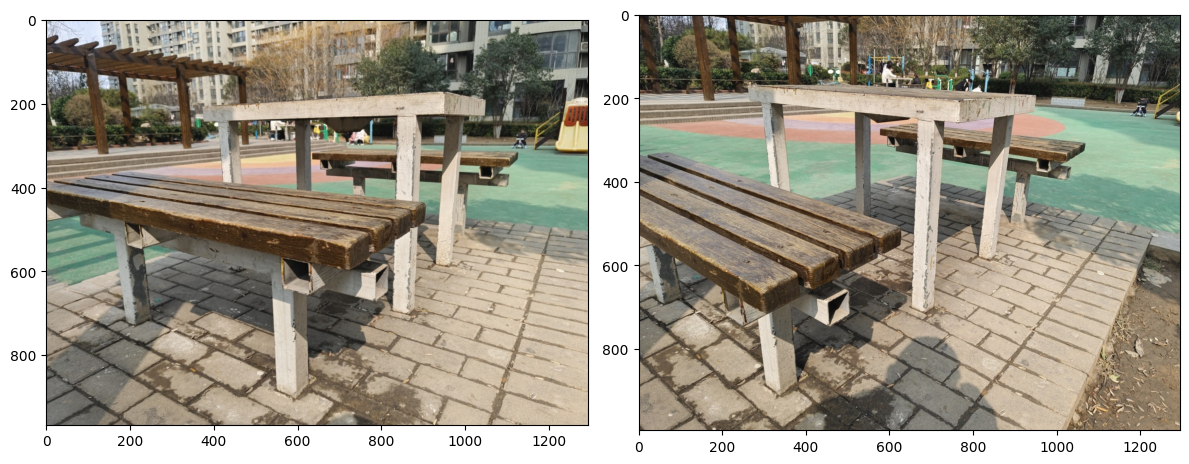

(38, 22)
(39, 22)
(40, 22)
(41, 22)
(42, 22)
(43, 22)
(44, 22)
(45, 22)
(46, 22)
(0, 23)
(1, 23)
(2, 23)
(3, 23)
(4, 23)
(5, 23)
(6, 23)
(7, 23)
(8, 23)
(9, 23)
(10, 23)
(11, 23)
(12, 23)
(13, 23)
(14, 23)
(15, 23)
(16, 23)
(17, 23)
(18, 23)
(19, 23)
(20, 23)
(21, 23)
(22, 23)
(23, 23)
(24, 23)
(25, 23)
(26, 23)
(27, 23)
(28, 23)
(29, 23)
(30, 23)
(31, 23)
(32, 23)
(33, 23)
(34, 23)
(35, 23)
(36, 23)
(37, 23)
(38, 23)
(39, 23)
(40, 23)
(41, 23)
(42, 23)
(43, 23)
(44, 23)
(45, 23)
(46, 23)
(0, 24)
(1, 24)
(2, 24)
(3, 24)
(4, 24)
(5, 24)
(6, 24)
(7, 24)
(8, 24)
(9, 24)
(10, 24)
(11, 24)
(12, 24)
(13, 24)
(14, 24)
(15, 24)
(16, 24)
(17, 24)
(18, 24)
(19, 24)
(20, 24)
(21, 24)
(22, 24)
(23, 24)
(24, 24)
(25, 24)
(26, 24)
(27, 24)
(28, 24)
(29, 24)
(30, 24)
(31, 24)
(32, 24)
(33, 24)
(34, 24)
(35, 24)
(36, 24)
(37, 24)
(38, 24)
(39, 24)
(40, 24)
(41, 24)
(42, 24)
(43, 24)
(44, 24)
(45, 24)
(0, 25)
(1, 25)
(2, 25)
(3, 25)
(4, 25)
(5, 25)
(6, 25)
(7, 25)
(8, 25)
(9, 25)
(10, 25)
(11, 25)
(12,

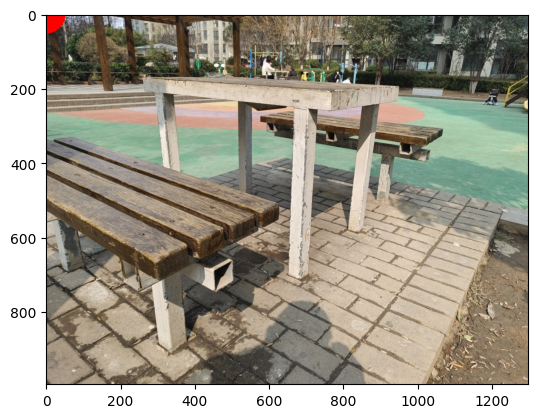